# CS4207 Coding Challenge | Parallel Taxi Tip Prediction

**Group 8 · University of Limerick**

Given a completed NYC yellow taxi ride paid by card, predict whether the passenger leaves a recorded tip (`tip_amount > 0`). A logistic regression model provides the workload for comparing **data parallelism**, **task parallelism** and **reproducibility**.

This notebook uses the **January 2026** TLC file. It trains on 1–17 January, tunes on 18–24 January, and evaluates on 25–31 January. Cash tips are unrecorded in the source, so all model results describe card trips.

| Section | What to look for |
|---|---|
| 0–2 | Verified dataset, cleaning counts, time split and sequential reference model |
| 3–4 | Day shards, equivalent sequential and parallel aggregates, speedup and overheads |
| 5 | Independent model trials and independent feature groups, with timing and equivalence checks |
| 6 | Two sources of nondeterminism and repeatable fixes |
| 7 | Hardware, software versions, overall runtime and output files |

**How the code connects:** the cleaned table feeds the feature and model pipeline. The day-shard experiment separately reads, cleans and aggregates the same trips by pickup zone and hour, and checks that result against direct aggregation. The feature extraction experiment reproduces the sequential feature table; the search experiment runs independent model fits on the same training and validation inputs.

Open the notebook from the project root so it can import the worker functions in `src/`. The accompanying README gives the local and Slurm commands.

## 0. Setup and configuration

In [1]:
import os
import time

from src import config as C

NOTEBOOK_START = time.perf_counter()

# Apply the numerical thread limit before importing NumPy or scikit-learn.
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
                 "VECLIB_MAXIMUM_THREADS", "BLIS_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[variable] = C.THREADS_PER_WORKER

import pickle
import warnings
from concurrent.futures import ProcessPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
from threadpoolctl import threadpool_limits

from src import data, feature_tasks, features, model, parallel, search, utils

# Limit libraries already loaded by the notebook kernel as well.
thread_limits = threadpool_limits(limits=int(C.THREADS_PER_WORKER))
pa.set_cpu_count(int(C.THREADS_PER_WORKER))
pd.set_option("display.float_format", "{:,.4f}".format)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
np.random.seed(C.SEED)

C.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
C.CACHE_DIR.mkdir(parents=True, exist_ok=True)

print(data.ensure_data())
data_sha256 = data.verify_data()
print("Dataset:", C.DATA_SOURCE)
print("SHA-256:", data_sha256)
print("Seed:", C.SEED, "| Workers:", C.WORKER_COUNTS, "| Timed repeats:", C.N_REPEATS)
print(f"Split: train < {C.TRAIN_END} ≤ validation < {C.VAL_END} ≤ test")

Found yellow_tripdata_2026-01(1).parquet (61 MiB).
Dataset: NYC TLC Yellow Taxi Trip Records, January 2026 (Parquet)
SHA-256: 8b3933fe6f0d7b6d8826613c0dd724edc680ff7c49e2bd4c7635c05102728637
Seed: 4207 | Workers: [1, 2, 4, 8] | Timed repeats: 3
Split: train < 2026-01-18 ≤ validation < 2026-01-25 ≤ test


Configuration lives in `src/config.py`. The hash check verifies that every run uses the same January release. By default the notebook uses `data/raw/` and downloads the file from NYC TLC if it is absent. Rockhill can use its existing copy via `TIP_DATA_FILE`.

Each worker gets one numerical thread to limit competition between workers. The data-parallel shards also use single-threaded batch reads and conversion. Separate measures capture the cost of starting the worker pool.

In [2]:
env = utils.environment_info()
environment_table = pd.Series(env, name="value").to_frame()
environment_table.to_csv(C.OUTPUT_DIR / "environment.csv", index_label="setting")

if env["usable_cpus"] < max(C.WORKER_COUNTS):
    print(f"Only {env['usable_cpus']} CPUs are available; higher worker counts oversubscribe them.")

environment_table

,value
python,3.12.14
platform,Linux-6.18.57-x86_64-with-glibc2.41
cpu_model,AMD EPYC 9V45 96-Core Processor
os.cpu_count(),9
usable_cpus,8
execution_host,Local execution environment
process_start_method,fork
slurm_job_id,-
numpy,2.5.5
pandas,3.1.1


The table records the exact environment for the saved results. On Slurm the available CPU count also respects the job allocation. A standalone run has no Slurm job ID. Python requirements are pinned in `requirements.txt`.

## 1. Data cleaning and preprocessing

### 1.1 Inspect the Parquet footer before loading anything

In [3]:
total_rows, row_groups, schema = data.parquet_summary()
print(f"{total_rows:,} rows in {len(row_groups)} row groups")
print(schema)
row_groups

3,724,889 rows in 4 row groups
VendorID: int32
tpep_pickup_datetime: timestamp[us]
tpep_dropoff_datetime: timestamp[us]
passenger_count: int64
trip_distance: double
RatecodeID: int64
store_and_fwd_flag: large_string
PULocationID: int32
DOLocationID: int32
payment_type: int64
fare_amount: double
extra: double
mta_tax: double
tip_amount: double
tolls_amount: double
improvement_surcharge: double
total_amount: double
congestion_surcharge: double
Airport_fee: double
cbd_congestion_fee: double


,row_group,rows
0,0,1048576
1,1,1048576
2,2,1048576
3,3,579161


**What this does:** reads only the Parquet *footer* (metadata at the end of the file), so we learn the row count, row groups and column types without loading any data.
This tells us the file has only **4 row groups**, which matters later: sharding by row group would give at most 4 tasks, not enough for 8 workers (see Section 3).

### 1.2 Why only card trips

In [4]:
data.payment_type_counts()

,trips
0 (Flex Fare),1088058
1 (Credit card),2249747
2 (Cash),314043
3 (No charge),16641
4 (Dispute),56400


The NYC TLC [Yellow Taxi data dictionary](https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf) describes `tip_amount` as the recorded credit card tip. Cash tips are unrecorded. We keep explicit card payments (`payment_type == 1`) and retain genuine zero recorded tips in that cohort. The same filter excludes the Flex Fare rows, where fields such as passenger count and rate code are often missing. The analysis makes no assumption about whether passengers tip on the excluded trips.

### 1.3 Cleaning steps and thresholds

| Step | Rule | Reason |
|---|---|---|
| Payment and date | Card payments; January pickups | Gives a consistent label and removes pickups outside the target month. |
| Distance | Greater than 0; at most 100 miles | The 99.99th percentile among January card trips is about 54 miles; the cap trims extreme meter readings. |
| Meter fare | Greater than $0; at most $500 | Removes zero/negative charges and trims unusually high metered fares. |
| Duration | 1–180 minutes | Removes zero or negative durations and extremely short or long readings. The 99.9th percentile is about 139 minutes. |
| Average speed | At most 80 mph | Screens for inconsistencies between measured time and distance. |
| Tip | At least $0 | A negative recorded tip is outside the definition of the binary target. |

In [5]:
thresholds = data.threshold_evidence()
thresholds.to_csv(C.OUTPUT_DIR / "cleaning_thresholds.csv", index=False)
thresholds

,statistic,value,note
0,Maximum distance in raw file (mi),"269,097.4800",all payment types; Parquet footer
1,Maximum distance in January card trips (mi),"98,773.5800",after card and date filters
2,Card-trip distance 99.99th percentile (mi),53.6000,threshold 100 mi
3,January card trips with distance > threshold,18.0000,flagged
4,duration 99.9th percentile (min),138.8333,threshold 180 min
5,trips with duration <= 0 min,"39,195.0000",flagged
6,trips with fare < 0,267.0000,flagged
7,trips with fare > threshold,4.0000,threshold $500


The **269,097.48-mile** maximum is from the full raw file. After the card and January filters, the maximum is **98,773.58 miles**. Those are different populations; the 100-mile cap applies to the January card cohort. Counts in the table above are independent flags in that cohort. The next table shows how many rows each rule removes when applied in sequence.

In [6]:
t0 = time.perf_counter()
df, cleaning_steps = data.load_clean()
print(f"load_clean(): {time.perf_counter() - t0:.1f} s, {len(df):,} rows kept "
      f"({len(df) / cleaning_steps.rows_after.iloc[0]:.1%} of raw)")
cleaning_steps.to_csv(C.OUTPUT_DIR / "cleaning_steps.csv", index=False)
cleaning_steps

load_clean(): 0.9 s, 2,186,454 rows kept (58.7% of raw)


,step,rows_after,removed
0,Raw file (from Parquet footer),3724889,0
1,"Card payments only (drops cash, Flex Fare, dis...",2249747,1475142
2,Pickup in 2026-01 (drops Dec/Feb spill-over),2249744,3
3,trip_distance > 0,2231495,18249
4,trip_distance <= 100 mi (meter errors),2231477,18
5,0 < fare_amount <= 500,2231413,64
6,1 <= duration <= 180 min,2186541,44872
7,average speed <= 80 mph,2186454,87
8,tip_amount >= 0,2186454,0


The loader reads just the projected columns and applies an Arrow filter for card payments. Each cleaning rule records its own row count.

**No tip leakage:** the recorded tip defines the label. Meter fare, duration and the other features come from the completed trip before the tip is entered. The total charge includes the tip, so it is excluded. Pickup zone, dropoff zone and rate code are treated as categories, with the encoder fitted on the training data.

### 1.4 Time-based split

In [7]:
train, val, test = data.time_split(df)
train_index, val_index, test_index = train.index, val.index, test.index
assert len(train) + len(val) + len(test) == len(df)
assert train.tpep_pickup_datetime.max() < val.tpep_pickup_datetime.min()
assert val.tpep_pickup_datetime.max() < test.tpep_pickup_datetime.min()

split_table = pd.DataFrame({
    "rows": [len(part) for part in (train, val, test)],
    "from": [part.tpep_pickup_datetime.min() for part in (train, val, test)],
    "to": [part.tpep_pickup_datetime.max() for part in (train, val, test)],
    "tip_rate": [part.tipped.mean() for part in (train, val, test)],
}, index=["train", "validation", "test"])
split_table.to_csv(C.OUTPUT_DIR / "time_split.csv", index_label="split")
del train, val, test
split_table

,rows,from,to,tip_rate
train,1224797,2026-01-01 00:00:09,2026-01-17 23:59:59,0.9036
validation,534239,2026-01-18 00:00:01,2026-01-24 23:59:59,0.9113
test,427418,2026-01-25 00:00:02,2026-01-31 23:59:56,0.9097


The split keeps the earlier rides for training and the latest week for the test. About nine in ten card trips have a recorded tip. This makes an always-tip predictor look strong on accuracy and positive-class F1. We also report ROC-AUC and balanced accuracy, with a majority-class comparison on the same test rides.

## 2. Features and baseline model (sequential reference)

In [8]:
t0 = time.perf_counter()
X = features.make_features(df)
y = df["tipped"]
assert {"tip_amount", "total_amount", "tipped"}.isdisjoint(X.columns)
print(f"Sequential feature table: {X.shape[0]:,} rides × {X.shape[1]} features")
print(f"Feature extraction took {time.perf_counter() - t0:.3f} s.")
X.head(3)

Sequential feature table: 2,186,454 rides × 18 features
Feature extraction took 0.134 s.


,hour,day_of_week,is_weekend,trip_distance,log_distance,duration_min,speed_mph,fare_amount,fare_per_mile,has_tolls,has_airport_fee,has_cbd_fee,passenger_count,PULocationID,DOLocationID,RatecodeID,pickup_airport,dropoff_airport
0,0,3,0,3.7000,1.5476,11.2500,19.7333,18.4000,4.9730,0,0,1,1,262,79,1,0,0
1,0,3,0,2.9300,1.3686,25.7833,6.8184,22.6000,7.7133,0,0,1,3,88,107,1,0,0
2,0,3,0,8.9300,2.2956,23.5167,22.7838,38.0000,4.2553,1,0,1,1,162,102,1,0,0


**What this does:** builds four independent **feature groups** (`src/features.py`):
- **time**: hour, day of week, weekend flag
- **distance**: distance, log distance, duration, average speed
- **fare**: fare, fare per mile, toll / airport / congestion-zone flags, passenger count
- **zone**: pickup and dropoff zone, rate code, airport pickup/dropoff flags

None of them use the tip. `make_features` runs them one after another and is the **sequential reference** that the parallel version in 5.2 must reproduce exactly.

In [9]:
Xtr, Xva, Xte = X.loc[train_index], X.loc[val_index], X.loc[test_index]
ytr, yva, yte = y.loc[train_index], y.loc[val_index], y.loc[test_index]

t0 = time.perf_counter()
baseline, val_scores = model.train_eval(Xtr, ytr, Xva, yva)
print(f"Baseline logistic regression trained in {time.perf_counter() - t0:.1f} s.")
pd.Series(val_scores, name="validation").to_frame()

Baseline logistic regression trained in 5.6 s.


,validation
f1,0.9776
roc_auc,0.8358
accuracy,0.9583
balanced_accuracy,0.7650


**What this does:** trains a logistic regression with default settings (zones one-hot encoded, numbers standardised) and scores it on the **validation** set.
This is the baseline that hyperparameter search (5.1) tries to improve. Each fit takes a few seconds, which makes it a good unit of work to run in parallel.

In [10]:
CLEAN_CACHE = C.CACHE_DIR / "clean.pkl"
MODEL_CACHE = C.CACHE_DIR / "model_data.pkl"
df.to_pickle(CLEAN_CACHE)

tuning_train = search.select_tuning_rows(ytr, C.SEARCH_TRAIN_ROWS)
tuning_val = search.select_tuning_rows(yva, C.SEARCH_VAL_ROWS)
search_index = tuning_train.union(tuning_val)
search_split = pd.Series("val", index=search_index)
search_split.loc[tuning_train] = "train"
X.loc[search_index].assign(tipped=y.loc[search_index], split=search_split).to_pickle(MODEL_CACHE)

tuning_table = pd.DataFrame({
    "full_rows": [len(ytr), len(yva)],
    "tuning_rows": [len(tuning_train), len(tuning_val)],
    "tuning_tip_rate": [y.loc[tuning_train].mean(), y.loc[tuning_val].mean()],
}, index=["train", "validation"])
tuning_table.to_csv(C.OUTPUT_DIR / "tuning_split.csv", index_label="split")
tuning_table

,full_rows,tuning_rows,tuning_tip_rate
train,1224797,200000,0.9036
validation,534239,100000,0.9113


The cleaned table is cached for the feature workers. The model-search cache holds fixed stratified samples from the training and validation folds, selected once with the shared seed. This limits per-worker memory and keeps all search timings comparable. The samples stay inside their time folds, and the test rides are excluded.

## 3. Data parallelism

Partition the raw January records by pickup day. Every worker reads and cleans its assigned days using the same rules, then returns three partial values for each pickup zone and hour: trip count, tipped trip count and the sum of the tip-to-meter-fare ratios. The main process adds the partials and computes the rates from those merged sums and counts.

The aggregate is a separate workload from classification and uses the recorded tips only to describe the historical rides.

31 pickup-day shards, 3,724,882 raw January rows.
Smallest 44,858; largest 153,101; max/min 3.4×.


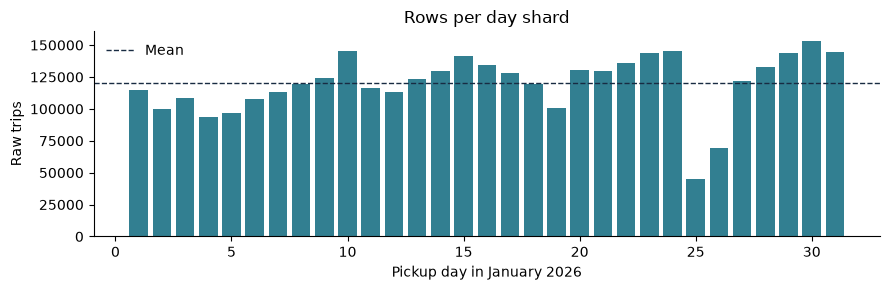

In [11]:
shards = parallel.write_day_shards()
shards[["shard_id", "rows"]].to_csv(C.OUTPUT_DIR / "shard_sizes.csv", index=False)
print(f"{len(shards)} pickup-day shards, {shards.rows.sum():,} raw January rows.")
print(f"Smallest {shards.rows.min():,}; largest {shards.rows.max():,}; "
      f"max/min {shards.rows.max() / shards.rows.min():.1f}×.")

fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(shards.shard_id, shards.rows, color="#327F91")
ax.axhline(shards.rows.mean(), color="#182B42", ls="--", lw=1, label="Mean")
ax.set(xlabel="Pickup day in January 2026", ylabel="Raw trips", title="Rows per day shard")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(C.OUTPUT_DIR / "shard_sizes.png", dpi=200)
plt.show()

The source file has four Parquet row groups. Using pickup days instead gives the pool 31 independent tasks. Shards are rebuilt from projected columns in streaming batches; pickups outside January are excluded during this preparation step.

Daily volume varies, so larger shards enter the worker queue first. Each worker can take another day when it finishes. Section 4 reports the remaining imbalance. The benchmark begins after sharding, for both sequential and parallel runs.

### 3.2 Run sequentially and in parallel, and verify

In [12]:
seq_merged, seq_results = parallel.run_data_parallel(shards, workers=0)
par_merged, par_results = parallel.run_data_parallel(shards, workers=max(C.WORKER_COUNTS))
reference = parallel.sequential_reference(df)

parallel.assert_same_aggregates(seq_merged, reference)
parallel.assert_same_aggregates(par_merged, reference)
assert sum(result["clean_rows"] for result in par_results) == len(df)

print("Sequential, parallel and direct aggregates agree.")
print(f"{len(par_merged):,} zone/hour groups; {int(par_merged.trips.sum()):,} trips.")
print("Shard float sums match exactly:", par_merged["tip_pct_sum"].equals(seq_merged["tip_pct_sum"]))

Sequential, parallel and direct aggregates agree.
5,203 zone/hour groups; 2,186,454 trips.
Shard float sums match exactly: True


The sequential loop and process pool both call the same shard worker. An independent check groups the cleaned full table directly. All group keys and integer counts must match exactly, and floating-point aggregates must agree to a relative tolerance of 10⁻¹².

The merge adds **counts and sums first**, then divides. If we averaged each day's rate equally, a quiet day would have the same influence as a busy day.

In [ ]:
import multiprocessing as mp
full_df_mb = df.memory_usage(deep=True).sum() / 2**20
with ProcessPoolExecutor(max_workers=max(C.WORKER_COUNTS), mp_context=mp.get_context("spawn")) as pool:
    _, spawn_results = parallel.run_data_parallel(shards, pool=pool)
fresh_peak = max(r["peak_rss_mb"] for r in spawn_results)
print(f"Full cleaned table: {full_df_mb:,.0f} MiB.")
print(f"Peak memory of a freshly started worker: {fresh_peak:,.0f} MiB "
      f"(reads batches of {C.BATCH_SIZE:,} rows).")

Full cleaned table: 196 MiB.
Largest observed worker peak RSS: 868 MiB (read batches of 32,768 rows).


Workers use iter_batches to bound the number of raw rows held at once, keeping only small partial aggregate tables for their day. For this measurement the workers start as fresh processes, so the peak includes the Python interpreter and libraries but no memory copied from the notebook process.

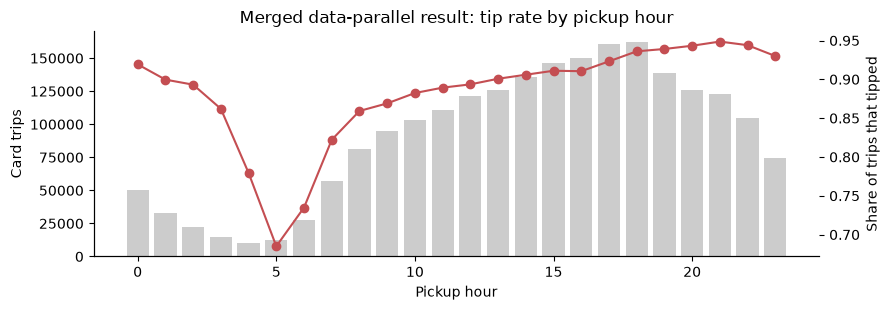

In [14]:
by_hour = par_merged.groupby(level="hour")[["trips", "tipped"]].sum()
by_hour["tip_rate"] = by_hour.tipped / by_hour.trips
fig, ax1 = plt.subplots(figsize=(9, 3.2))
ax1.bar(by_hour.index, by_hour.trips, color="#ccc", label="card trips")
ax1.set(xlabel="Pickup hour", ylabel="Card trips")
ax2 = ax1.twinx()
ax2.plot(by_hour.index, by_hour.tip_rate, "o-", color="#C44E52", label="tip rate")
ax2.set_ylabel("Share of trips that tipped")
ax1.set_title("Merged data-parallel result: tip rate by pickup hour")
fig.tight_layout()
fig.savefig(C.OUTPUT_DIR / "tip_rate_by_hour.png", dpi=150)
plt.show()

**What this does:** uses the merged data-parallel output for an actual finding: how tip rate changes over the day (red), against trip volume (grey bars). It shows the partial-sum merge produces something meaningful, and is a candidate figure for the poster.

## 4. Sequential and parallel benchmark

Every benchmark run reads, cleans and aggregates all 31 shards, then merges the results. The sequential baseline uses a plain loop. For each worker count we measure a **warm pool** and a **fresh pool**. The latter includes pool startup and shutdown; both measurements use one warm-up and three timed repeats. Aggregate checks run outside the stopwatch after every repeat.

In [15]:
def check_aggregates(result):
    merged, _ = result
    parallel.assert_same_aggregates(merged, reference)

_, t1_mean, t1_std, _ = utils.time_it(
    parallel.run_data_parallel, shards, workers=0, check=check_aggregates,
)
rows = [{
    "workers": 1, "version": "sequential loop",
    "mean_s": t1_mean, "std_s": t1_std, "cold_mean_s": t1_mean, "cold_std_s": t1_std,
}]

for workers in C.WORKER_COUNTS:
    with ProcessPoolExecutor(max_workers=workers) as pool:
        (_, results), warm_mean, warm_std, _ = utils.time_it(
            parallel.run_data_parallel, shards, pool=pool, check=check_aggregates,
        )
    _, cold_mean, cold_std, _ = utils.time_it(
        parallel.run_data_parallel, shards, workers=workers, check=check_aggregates,
    )
    rows.append({
        "workers": workers, "version": "process pool",
        "mean_s": warm_mean, "std_s": warm_std,
        "cold_mean_s": cold_mean, "cold_std_s": cold_std,
        "pool_startup_probe_s": float(np.mean([
            parallel.pool_startup_seconds(workers) for _ in range(C.N_REPEATS)
        ])),
        "results_pickled_mib": len(pickle.dumps(results)) / 2**20,
        **parallel.load_balance(results),
    })

bench = pd.DataFrame(rows)
bench["speedup"] = t1_mean / bench["mean_s"]
bench["efficiency"] = bench["speedup"] / bench["workers"]
bench["speedup_incl_startup"] = t1_mean / bench["cold_mean_s"]
bench["efficiency_incl_startup"] = bench["speedup_incl_startup"] / bench["workers"]
bench["karp_flatt_serial_frac"] = np.nan
multi = bench["workers"] > 1
reciprocal_workers = 1 / bench.loc[multi, "workers"]
bench.loc[multi, "karp_flatt_serial_frac"] = (
    (1 / bench.loc[multi, "speedup"] - reciprocal_workers) / (1 - reciprocal_workers)
)
bench.to_csv(C.OUTPUT_DIR / "benchmark_data_parallel.csv", index=False)
bench[["workers", "version", "mean_s", "std_s", "speedup", "efficiency", "cold_mean_s",
       "speedup_incl_startup", "pool_startup_probe_s", "imbalance_max_over_mean"]]

,workers,version,mean_s,std_s,speedup,efficiency,cold_mean_s,speedup_incl_startup,pool_startup_probe_s,imbalance_max_over_mean
0,1,sequential loop,1.3891,0.0546,1.0000,1.0000,1.3891,1.0000,NaN,NaN
1,1,process pool,1.4373,0.0381,0.9665,0.9665,1.4768,0.9406,0.0216,1.0000
2,2,process pool,0.6997,0.0184,1.9853,0.9926,0.8110,1.7127,0.0267,1.0074
3,4,process pool,0.3718,0.0025,3.7356,0.9339,0.4893,2.8390,0.0364,1.0350
4,8,process pool,0.2102,0.0028,6.6072,0.8259,0.3210,4.3273,0.0434,1.0757


**Speedup** is sequential time divided by parallel time. **Efficiency** divides that speedup by worker count. The independent startup probe times a pool running trivial work. The fresh-pool measurement above times the full real workload, so it captures startup, shutdown and any interaction with the workload. Pickled response size estimates the amount returned by workers. Load imbalance compares the busiest worker’s time with the worker mean.

8 workers: 6.61× warm speedup (83% efficiency), 4.33× with a fresh pool.
Effective parallel fraction: 98.0%; fitted Amdahl limit: 49.1×.


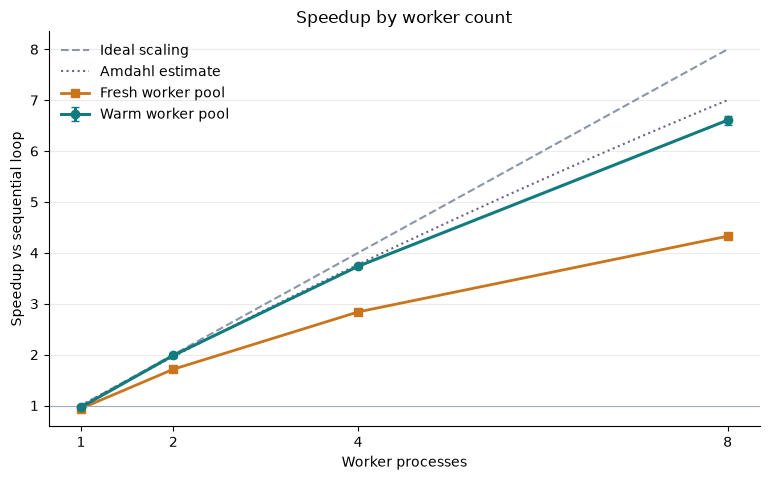

In [ ]:
par = bench[bench.version == "process pool"]
design = np.column_stack([np.ones(len(par)), 1 / par.workers.to_numpy()])

def amdahl_fit(times):
    """Least-squares fit of Tp = a + b/p: serial s, parallel s, std error of a."""
    coef, *_ = np.linalg.lstsq(design, times, rcond=None)
    resid = times - design @ coef
    se = np.sqrt(resid @ resid / (len(times) - 2) * np.linalg.inv(design.T @ design)[0, 0])
    return coef[0], coef[1], se

a_warm, b_warm, se_warm = amdahl_fit(par.mean_s.to_numpy())
a_cold, b_cold, _ = amdahl_fit(par.cold_mean_s.to_numpy())
serial_frac = a_cold / (a_cold + b_cold)
parallel_frac = 1 - serial_frac

fig, ax = plt.subplots(figsize=(7.8, 4.9))
worker_counts = np.array(C.WORKER_COUNTS)
ax.plot(worker_counts, worker_counts, "--", color="#8B97A7", label="Ideal scaling")
if 0 < serial_frac < 1:
    worker_grid = np.linspace(1, worker_counts.max(), 60)
    amdahl = t1_mean / (a_cold + b_cold / worker_grid)
    ax.plot(worker_grid, amdahl, ":", color="#706086", label="Amdahl fit (fresh pool)")
ax.errorbar(
    par.workers, par.speedup, yerr=par.speedup * par.std_s / par.mean_s,
    marker="o", color="#117B7E", lw=2.2, capsize=3, label="Warm worker pool",
)
ax.plot(par.workers, par.speedup_incl_startup, "s-", color="#CA741B", lw=2.0, label="Fresh worker pool")
ax.axhline(1, color="#A4ADBA", lw=0.8)
ax.set(xlabel="Worker processes", ylabel="Speedup vs sequential loop",
       xticks=worker_counts, title="Speedup by worker count")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(C.OUTPUT_DIR / "speedup.png", dpi=260)
plt.show()

largest = par.iloc[-1]
print(f"{int(largest.workers)} workers: {largest.speedup:.2f}× warm speedup "
      f"({largest.efficiency:.0%} efficiency), {largest.speedup_incl_startup:.2f}× with a fresh pool.")
warm_note = ("not distinguishable from zero" if abs(a_warm) < 2 * se_warm
             else "measurable")
print(f"Warm pool: fitted serial time {a_warm:.3f} ± {se_warm:.3f} s of {a_warm + b_warm:.2f} s "
      f"({warm_note}).")
print(f"Fresh pool: fitted serial time {a_cold:.2f} s ({serial_frac:.0%}), "
      f"parallel fraction {parallel_frac:.0%}, Amdahl limit {1 / serial_frac:.1f}×.")

Amdahl’s law models speedup as `1 / ((1 - f) + f/p)`, where `f` is the parallel fraction and `p` is the number of workers. We estimate the effective parallel fraction from the average Karp–Flatt serial fraction over 2, 4 and 8 warm workers. It includes overhead and is an empirical fit for these runs.

Workers share disk and memory bandwidth, return partial tables, and sometimes finish unevenly. The main process still combines those partials, and the fresh pool pays a startup cost. The chart separates that full-run result from a pool that's already active. All displayed values belong to the hardware shown in Section 7.

## 5. Task parallelism

### 5.1 Pattern 1: hyperparameter search

A trial is an independent model fit with its own settings. Each trial uses the same fixed training and validation samples, so trials can run at the same time and each worker can reuse its input. The full training and test folds are used for the final model after settings are selected.

In [17]:
grid = search.make_grid(C.GRID_C, C.GRID_CLASS_WEIGHT)
print(f"{len(grid)} independent model settings.")

identity_columns = ["trial_id", "C_reg", "class_weight"]
score_columns = ["val_f1", "val_roc_auc"]

def check_trials(result):
    pd.testing.assert_frame_equal(result[identity_columns], grid_seq[identity_columns])
    np.testing.assert_allclose(result[score_columns], grid_seq[score_columns], rtol=1e-12, atol=0)

with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    grid_seq, seq_mean, seq_std, _ = utils.time_it(
        search.run_search, grid, workers=0, cache_path=MODEL_CACHE,
    )
    grid_rows = [{"workers": 1, "version": "sequential loop", "seconds": seq_mean, "std_s": seq_std}]
    for workers in [count for count in C.WORKER_COUNTS if count > 1]:
        _, mean, std, _ = utils.time_it(
            search.run_search, grid, workers=workers, cache_path=MODEL_CACHE, check=check_trials,
        )
        grid_rows.append({
            "workers": workers, "version": "process pool incl. data load",
            "seconds": mean, "std_s": std,
        })

grid_timing = pd.DataFrame(grid_rows)
grid_timing["speedup"] = seq_mean / grid_timing["seconds"]
grid_timing["efficiency"] = grid_timing["speedup"] / grid_timing["workers"]
grid_timing.to_csv(C.OUTPUT_DIR / "benchmark_hyperparameter_search.csv", index=False)
grid_timing

8 independent model settings.


,workers,version,seconds,std_s,speedup,efficiency
0,1,sequential loop,9.2754,0.4553,1.0000,1.0000
1,2,process pool incl. data load,5.5735,0.3027,1.6642,0.8321
2,4,process pool incl. data load,3.8548,0.1511,2.4062,0.6016
3,8,process pool incl. data load,2.8843,0.1949,3.2159,0.4020


Each worker reads the same sampled training and validation cache once, fits different settings, and returns the validation scores. Three measured runs include process startup, data load, training and shutdown. The checks compare every parallel trial’s settings and scores to the sequential results.

Last sequential pass: total fit time 9.9 s, slowest trial 2.5 s.


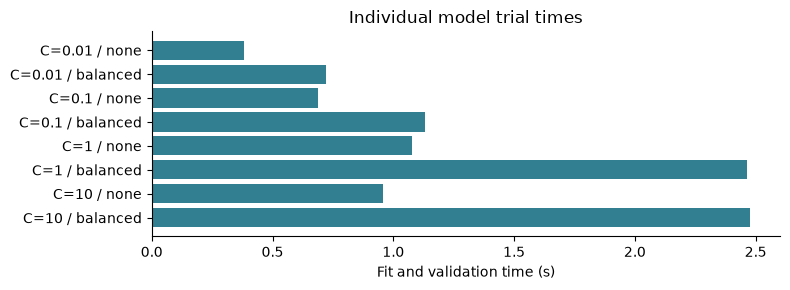

,trial_id,C_reg,class_weight,val_f1,val_roc_auc,seconds
0,0,0.0100,none,0.9779,0.8279,0.3830
1,1,0.0100,balanced,0.9682,0.8351,0.7203
2,2,0.1000,none,0.9779,0.8353,0.6876
3,3,0.1000,balanced,0.9626,0.8363,1.1294
4,4,1.0000,none,0.9779,0.8359,1.0773
5,5,1.0000,balanced,0.9618,0.8357,2.4636
6,6,10.0000,none,0.9779,0.8359,0.9578
7,7,10.0000,balanced,0.9618,0.8350,2.4769


In [18]:
grid_seq.drop(columns="pid").to_csv(C.OUTPUT_DIR / "grid_search_results.csv", index=False)
slowest_trial = grid_seq.seconds.max()
print(f"Last sequential pass: total fit time {grid_seq.seconds.sum():.1f} s, "
      f"slowest trial {slowest_trial:.1f} s.")

fig, ax = plt.subplots(figsize=(8, 3))
labels = [f"C={row.C_reg:g} / {row.class_weight}" for row in grid_seq.itertuples()]
ax.barh(labels, grid_seq.seconds, color="#327F91")
ax.invert_yaxis()
ax.set(xlabel="Fit and validation time (s)", title="Individual model trial times")
fig.tight_layout()
fig.savefig(C.OUTPUT_DIR / "trial_times.png", dpi=200)
plt.show()
grid_seq.drop(columns="pid")

Trial lengths vary with the settings. The last sequential pass shows the range. A pool cannot finish until its longest assigned trial has completed, and starting each process and loading its data add to elapsed time. With eight trials, eight workers leave little scope for a faster worker to pick up extra tasks.

In [19]:
best = grid_seq.loc[grid_seq.val_roc_auc.idxmax()]
best_params = {"C_reg": float(best.C_reg), "class_weight": best.class_weight}
print("Selected on validation:", best_params, f"| ROC-AUC {best.val_roc_auc:.4f}")

with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    final_model, test_scores = model.train_eval(Xtr, ytr, Xte, yte, **best_params)

test_table = pd.DataFrame({
    "default logistic (validation)": val_scores,
    "selected logistic (test)": test_scores,
    "majority baseline (test)": model.majority_scores(ytr, yte),
})
test_table.to_csv(C.OUTPUT_DIR / "model_results.csv", index_label="metric")
test_table

Selected on validation: {'C_reg': 0.1, 'class_weight': 'balanced'} | ROC-AUC 0.8363


,default logistic (validation),selected logistic (test),majority baseline (test)
f1,0.9776,0.9588,0.9527
roc_auc,0.8358,0.8188,0.5000
accuracy,0.9583,0.9249,0.9097
balanced_accuracy,0.7650,0.7591,0.5000


The validation ROC-AUC selects the regularisation and class weights. The selected model is fitted on the training rides and evaluated on the final week alongside a majority-label model. ROC-AUC assesses how well the model ranks tipped rides above untipped rides. Balanced accuracy is the mean recall of the two classes. Reporting both makes it easier to understand the high F1 that an always-tip predictor can get on an imbalanced dataset.

### 5.2 Pattern 2: feature extraction

**Why the tasks are independent:** each feature group (time, distance, fare, zone) reads only columns of the cleaned data and never another group's output. They can run in any order, in parallel, and are joined back in the **fixed order** of `FEATURE_GROUPS`, so the column order never depends on which task finished first.

In [20]:
def check_features(result):
    pd.testing.assert_frame_equal(result[0], X)

n_groups = len(features.FEATURE_GROUPS)
_, feat_seq_mean, feat_seq_std, _ = utils.time_it(features.make_features, df)
_, feat_cold_mean, feat_cold_std, _ = utils.time_it(
    feature_tasks.run_features_parallel, CLEAN_CACHE, workers=n_groups, check=check_features,
)
with ProcessPoolExecutor(max_workers=n_groups, initializer=feature_tasks.init_worker,
                         initargs=(CLEAN_CACHE,)) as pool:
    (X_warm, warm_results), feat_warm_mean, feat_warm_std, _ = utils.time_it(
        feature_tasks.run_features_on_pool, pool, check=check_features,
    )

feat_timing = pd.DataFrame({
    "version": ["sequential", "fresh pool", "warm pool"],
    "workers": [1, n_groups, n_groups],
    "mean_s": [feat_seq_mean, feat_cold_mean, feat_warm_mean],
    "std_s": [feat_seq_std, feat_cold_std, feat_warm_std],
})
feat_timing["speedup"] = feat_seq_mean / feat_timing["mean_s"]
feat_timing.to_csv(C.OUTPUT_DIR / "benchmark_feature_extraction.csv", index=False)
display(feat_timing)

groups = feature_tasks.group_timings(warm_results).drop(columns="pid")
groups.to_csv(C.OUTPUT_DIR / "feature_group_times.csv", index=False)
del X_warm, warm_results

print(f"All feature tables match exactly: {X.shape[0]:,} rows, {X.shape[1]} columns.")
print(f"The slowest group took {groups.seconds.max() / groups.seconds.sum():.0%} "
      "of the measured feature-group compute time in the last warm repeat.")
groups

All feature tables match exactly: 2,186,454 rows, 18 columns.
The slowest group took 40% of the measured feature-group compute time in the last warm repeat.


,version,workers,mean_s,std_s,speedup
0,sequential,1,0.1205,0.0002,1.0000
1,fresh pool,4,1.0803,0.0457,0.1116
2,warm pool,4,0.4705,0.0397,0.2561


,group,seconds,columns
0,time,0.0737,3
1,distance,0.0236,4
2,fare,0.0283,6
3,zone,0.0584,5


Four independent tasks build time, distance, fare and location features. Workers return their columns and the main process concatenates them in a fixed order. Every repeat checks for exact equality with the sequential feature table, including column order and dtypes.

The fresh pool includes worker startup and loading the cleaned table. The warm pool still pays for returning each result and joining the columns. The difference between the three timings shows when these costs cancel out any gain from dividing a short task. With unequal feature groups, no parallel run can finish before its longest task completes.

## 6. Non-determinism and fixes

For each source: (1) show two or more runs giving **different** output, (2) apply the fix, (3) re-run and show **identical** output.

### 6.1 Source 1: results collected in completion order

In [21]:
order_rows = []
for fixed in (False, True):
    for run in range(1, 4):
        order, total = parallel.completion_order_run(shards, workers=max(C.WORKER_COUNTS), fix=fixed)
        order_rows.append({
            "fixed": fixed, "run": run, "shard_order": ",".join(map(str, order)),
            "first_10_shards": ", ".join(map(str, order[:10])),
            "total_tip_ratio_sum": repr(float(total)),
        })

nd_order = pd.DataFrame(order_rows)
nd_order.to_csv(C.OUTPUT_DIR / "nondeterminism_completion_runs.csv", index=False)
before = nd_order[~nd_order.fixed]
after = nd_order[nd_order.fixed]

for label, run_table in [("Before", before), ("After", after)]:
    print(f"{label}: {run_table.shard_order.nunique()} distinct orders, "
          f"{run_table.total_tip_ratio_sum.nunique()} distinct totals.")
assert after.shard_order.nunique() == 1 and after.total_tip_ratio_sum.nunique() == 1
nd_order.drop(columns="shard_order")

Before: 3 distinct orders, 3 distinct totals.
After: 1 distinct orders, 1 distinct totals.


,fixed,run,first_10_shards,total_tip_ratio_sum
0,False,1,"5, 2, 7, 4, 3, 6, 8, 1, 9, 11",547020.0257592335
1,False,2,"4, 2, 5, 3, 7, 6, 1, 13, 11, 12",547020.0257592307
2,False,3,"4, 5, 8, 3, 2, 6, 7, 1, 11, 9",547020.0257592327
3,True,1,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10",547020.0257592333
4,True,2,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10",547020.0257592333
5,True,3,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10",547020.0257592333


The same workers and input shards can complete in a different order because of scheduling, I/O and unequal work. A running floating-point sum can change in its last digits when that order changes. The fix is to tag each partial result with its day and sort by that tag before accumulating. The comparisons use the complete 31-shard order; the table previews its first ten IDs. An untimed rerun can encounter less variation because it depends on actual scheduling.

### 6.2 Source 2: unseeded randomness in random search

In [22]:
rs_rows = []
rs_tables = {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    for label, seed in [("unseeded", None), ("unseeded", None), ("seeded", C.SEED), ("seeded", C.SEED)]:
        tasks = search.random_tasks(C.RANDOM_TRIALS, C.RANDOM_SAMPLE_SIZE, seed=seed)
        results = search.run_search(tasks, workers=max(C.WORKER_COUNTS), cache_path=MODEL_CACHE,
                                    trial_fn=search.random_trial)
        run = len(rs_rows) + 1
        rs_tables[run] = results
        selected = results.loc[results.val_roc_auc.idxmax()]
        rs_rows.append({
            "run": run, "seeding": label, "best_C_reg": selected.C_reg,
            "best_class_weight": selected.class_weight, "best_val_roc_auc": selected.val_roc_auc,
            "trial_table_hash": str(int(pd.util.hash_pandas_object(results).sum())),
        })

rs_summary = pd.DataFrame(rs_rows)
rs_summary.to_csv(C.OUTPUT_DIR / "nondeterminism_random_runs.csv", index=False)
rs_summary

,run,seeding,best_C_reg,best_class_weight,best_val_roc_auc,trial_table_hash
0,1,unseeded,0.0555,balanced,0.8322,7881615272276930177
1,2,unseeded,0.0796,none,0.8308,7077289943848353520
2,3,seeded,0.1244,balanced,0.8306,15469770564944540280
3,4,seeded,0.1244,balanced,0.8306,15469770564944540280


Each trial samples a setting and a 50,000-row subset of the tuning training sample. Unseeded trials draw fresh random numbers and can pick different winners. With the fix, `SeedSequence(SEED).spawn(n)` derives one distinct, repeatable seed per trial. The seed goes with the trial ID, so different worker assignments leave the draws the same. The next cell compares full result tables rather than relying on the fingerprints alone.

In [23]:
seeded_equal = rs_tables[3].equals(rs_tables[4])
unseeded_equal = rs_tables[1].equals(rs_tables[2])
assert seeded_equal and not unseeded_equal

nd_summary = pd.DataFrame([
    {
        "source": "Worker completion order",
        "before": f"{before.shard_order.nunique()} distinct orders; "
                  f"{before.total_tip_ratio_sum.nunique()} floating-point totals in 3 runs",
        "fix": "Tag each shard and sort by day before reducing.",
        "after": "One order and one total in 3 runs.",
    },
    {
        "source": "Unseeded random search",
        "before": "Two runs produced different trial tables.",
        "fix": "Generate independent and repeatable per-trial seeds.",
        "after": "Two seeded runs produced identical trial tables.",
    },
])
nd_summary.to_csv(C.OUTPUT_DIR / "nondeterminism_summary.csv", index=False)
with pd.option_context("display.max_colwidth", 100):
    display(nd_summary)

,source,before,fix,after
0,Worker completion order,3 distinct orders; 3 floating-point totals in 3 runs,Tag each shard and sort by day before reducing.,One order and one total in 3 runs.
1,Unseeded random search,Two runs produced different trial tables.,Generate independent and repeatable per-trial seeds.,Two seeded runs produced identical trial tables.


In [ ]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    tasks = search.random_tasks(C.RANDOM_TRIALS, C.RANDOM_SAMPLE_SIZE, seed=C.SEED)
    two_workers = search.run_search(tasks, workers=2, cache_path=MODEL_CACHE,
                                    trial_fn=search.random_trial)
assert two_workers.equals(rs_tables[3])
print("Seeded search with 2 workers gives the same trial table as with 8 workers.")

The fixes make output repeatable for a fixed environment. Wall-clock timings still vary, and a different BLAS library, hardware architecture or package version can alter last-digit floating-point results. We limit numerical threads and record package versions, and the main aggregate verification tolerates tiny differences between mathematically equivalent reductions.

## 7. Run summary

In [24]:
summary = {
    "total notebook run time (s)": round(time.perf_counter() - NOTEBOOK_START, 1),
    "execution host": env["execution_host"],
    "hardware": f"{env['cpu_model']}; {env['usable_cpus']} available logical CPUs",
    "usable_cpus": env["usable_cpus"],
    "GPU": "Not used; CPU workload",
    "slurm job": env["slurm_job_id"],
    "python": env["python"],
    "data": C.DATA_NAME,
    "data sha256": data_sha256,
    "rows raw": total_rows,
    "rows kept": len(df),
    "shards": len(shards),
    "workers": ", ".join(map(str, C.WORKER_COUNTS)),
    "benchmark repeats": C.N_REPEATS,
    "target": "Recorded tip > 0 on card trips",
    "model": "Logistic regression",
    "selected C": best_params["C_reg"],
    "selected class weight": best_params["class_weight"],
    "validation ROC-AUC": float(best.val_roc_auc),
    "aggregate verification": "Passed",
    "feature equivalence": "Passed",
    "search equivalence": "Passed",
    "seeded repeatability": "Passed",
}
summary_table = pd.Series(summary, name="value").to_frame()
summary_table.to_csv(C.OUTPUT_DIR / "run_summary.csv", index_label="setting")
summary_table

,value
total notebook run time (s),216.5000
execution host,Local execution environment
hardware,AMD EPYC 9V45 96-Core Processor; 8 available l...
usable_cpus,8
GPU,Not used; CPU workload
slurm job,-
python,3.12.14
data,yellow_tripdata_2026-01.parquet
data sha256,8b3933fe6f0d7b6d8826613c0dd724edc680ff7c49e2bd...
rows raw,3724889


The exported CSVs and figures are in the same output directory as the run summary. Use that set together when updating the poster. The README maps each poster figure and claim to the relevant notebook section and output.